Instalar las librerías

In [5]:
!pip install boto3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.6/139.6 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.4/84.4 kB 6.2 MB/s eta 0:00:00


Importar las librerías necesarias

In [6]:
import boto3
import pandas as pd
import configparser
import time
import plotly.express as px
from google.colab import drive

**Esta parte de la pueden saltar y en el siguiente, poner directamente sus credenciales, sin compartir el colab a nadie externo**

**En caso de querer usar el archivo de config, deben crear en su Drive base, un archivo de config.txt en este formato**
```
[aws]
aws_access_key_id = TU_ACCESS_KEY_ID
aws_secret_access_key = TU_SECRET_ACCESS_KEY
```
Obtener credenciales desde Drive

In [ ]:
drive.mount('/content/drive')

config = configparser.ConfigParser()
config.read('/content/drive/My Drive/config.txt')

**Como se dice antes, si no se hace con el archivo de config, se deben poner las credenciales directamente**

Configuración de AWS y Amazon Athena



In [ ]:
# Credenciales mediante el perfil AWS local o las variables de entorno de boto3.
# Se retiraron las claves incrustadas de la entrega universitaria.
region_name = 'us-east-1'
database = 'telephonic_campaigns'
client = boto3.client('athena', region_name=region_name)


Funciones para obtener los datos de Athena

In [8]:
def wait_for_query_completion(query_execution_id):
    while True:
        response = client.get_query_execution(QueryExecutionId=query_execution_id)
        status = response['QueryExecution']['Status']['State']
        if status in ['SUCCEEDED', 'FAILED', 'CANCELLED']:
            break

        print(f"Query is {status}.")
        time.sleep(5)

    return status

def return_query_execution_id(query):
    response = client.start_query_execution(
        QueryString=query,
        QueryExecutionContext={'Database': database},
        ResultConfiguration={'OutputLocation': 's3://curso-business-analytics/Unsaved/'}
    )
    return response['QueryExecutionId']

def get_query_results(query_execution_id):
    try:
      response = client.get_query_results(QueryExecutionId=query_execution_id)
      return response
    except Exception as e:
        print(f"Ocurrió un error: {e}")
    return None

Trabajar los datos para graficar

Query is QUEUED.
Query is RUNNING.


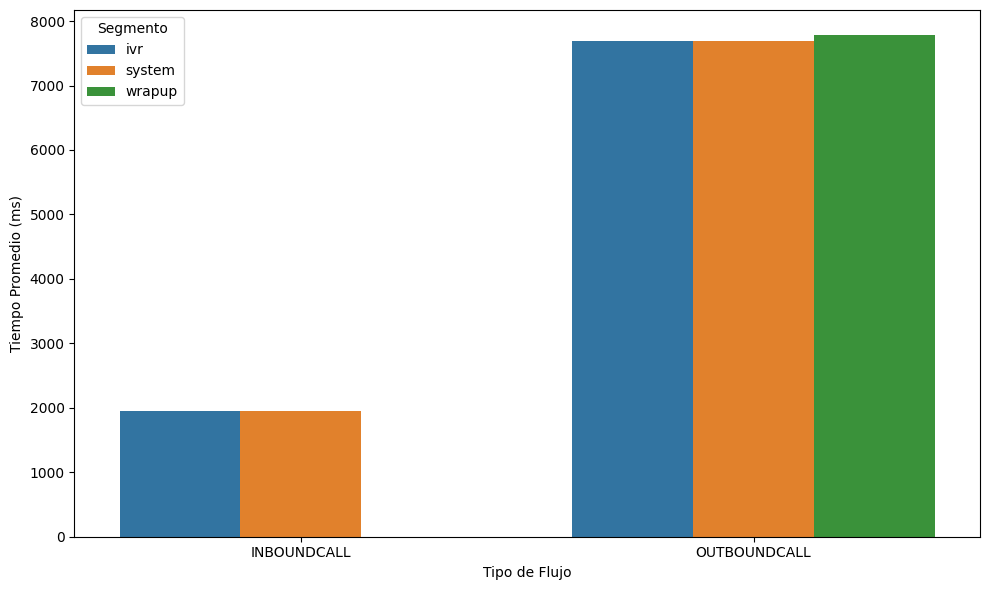

In [9]:
# Consulta para Gráfico 2
# Análisis de performance, calcula el promedio del nivel de calidad del audio (se mide en R-factor) para cada flujo y motivo de salida
query = '''
SELECT
    f.flow_type AS flujo,
    s.segment_type AS segmento,
    ROUND(AVG(ss.t_flow), 2) AS tiempo_promedio
FROM
    flows f
JOIN
    sessions ss ON f.session_id = ss.session_id
JOIN
    segments s ON ss.session_id = s.session_id
WHERE
    s.segment_type IN ('ivr', 'system', 'wrapup')
GROUP BY
    f.flow_type, s.segment_type
ORDER BY
    f.flow_type, s.segment_type
'''

query_execution_id = return_query_execution_id(query)
wait_for_query_completion(query_execution_id)
query_response = get_query_results(query_execution_id)

# Procesar resultado
columns = [col['Label'] for col in query_response['ResultSet']['ResultSetMetadata']['ColumnInfo']]
rows = []
for row in query_response['ResultSet']['Rows'][1:]:
    row_values = []
    for val in row['Data']:
        if 'VarCharValue' in val:
            row_values.append(val['VarCharValue'])
        else:
            row_values.append(None)
    rows.append(row_values)

# Crear DataFrame
df = pd.DataFrame(rows, columns=columns)
df['tiempo_promedio'] = pd.to_numeric(df['tiempo_promedio'])

# Gráfico de barras agrupadas por tipo de flujo y tipo de segmento
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='flujo', y='tiempo_promedio', hue='segmento')


plt.ylabel('Tiempo Promedio (ms)')
plt.xlabel('Tipo de Flujo')
plt.legend(title='Segmento')
plt.tight_layout()
plt.show()


Graficar

Query is QUEUED.
Query is RUNNING.


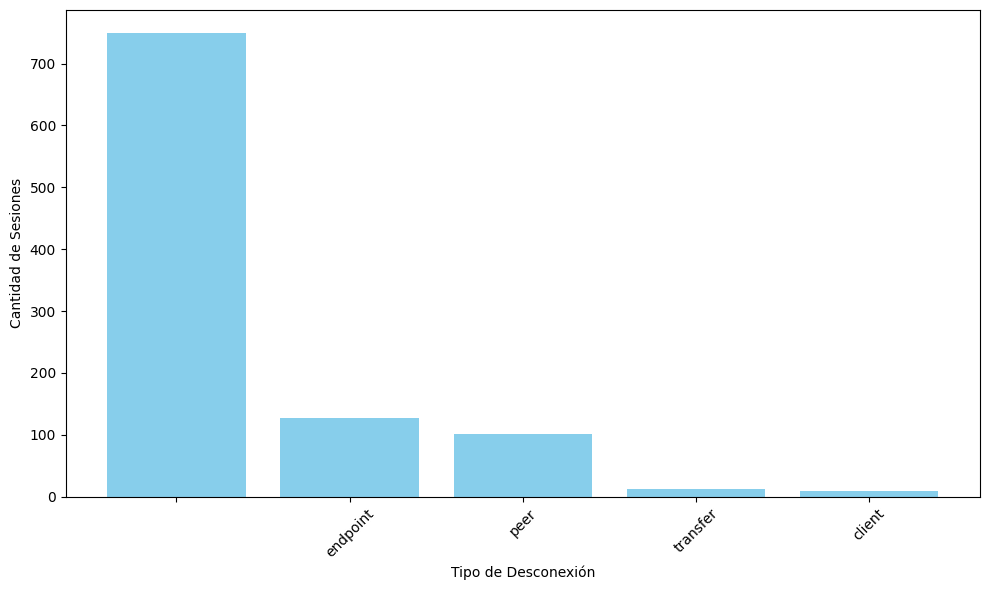

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Consulta SQL
query = '''
WITH ultimo_segmento AS (
  SELECT session_id, disconnect_type
  FROM (
    SELECT session_id, disconnect_type,
           ROW_NUMBER() OVER (PARTITION BY session_id ORDER BY segment_end DESC) AS rn
    FROM segments
  ) t
  WHERE rn = 1
)
SELECT s.session_id, u.disconnect_type
FROM sessions s
JOIN ultimo_segmento u ON s.session_id = u.session_id
WHERE s.media_type = 'voice';
'''

# Ejecutar la consulta
query_execution_id = return_query_execution_id(query)
wait_for_query_completion(query_execution_id)
query_response = get_query_results(query_execution_id)

# Extraer resultados y convertir en DataFrame
columns = [col['Label'] for col in query_response['ResultSet']['ResultSetMetadata']['ColumnInfo']]
rows = []
for row in query_response['ResultSet']['Rows'][1:]:
    row_values = []
    for val in row['Data']:
        if 'VarCharValue' in val:
            row_values.append(val['VarCharValue'])
        else:
            row_values.append(None)
    rows.append(row_values)

df = pd.DataFrame(rows, columns=columns)

# Agrupar por tipo de desconexión y contar
conteo_desconexiones = df['disconnect_type'].value_counts().reset_index()
conteo_desconexiones.columns = ['Tipo de Desconexión', 'Cantidad']

# Graficar
plt.figure(figsize=(10, 6))
plt.bar(conteo_desconexiones['Tipo de Desconexión'], conteo_desconexiones['Cantidad'], color='skyblue')
plt.xlabel('Tipo de Desconexión')
plt.ylabel('Cantidad de Sesiones')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Query is QUEUED.
Query is RUNNING.


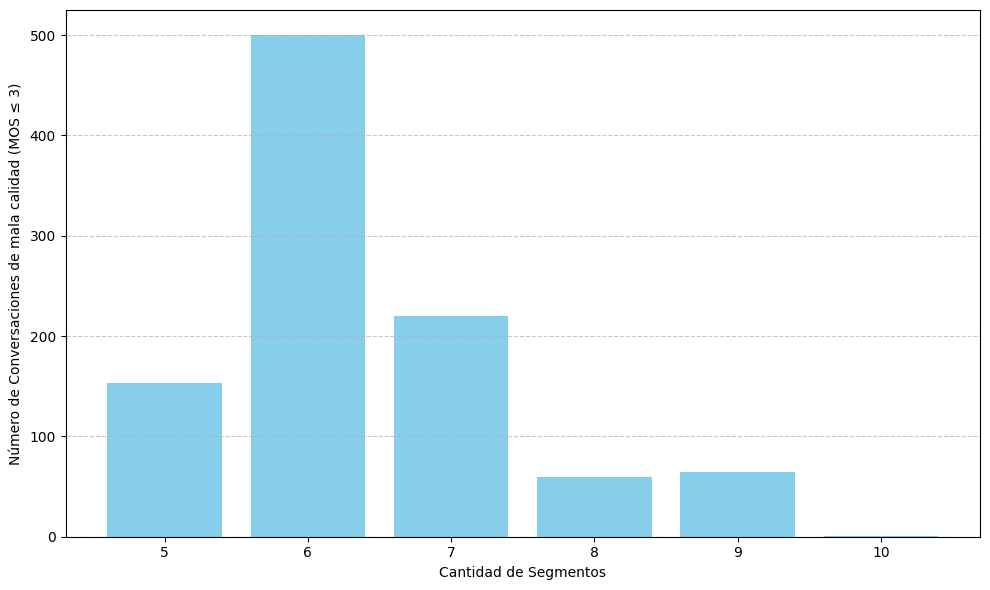

In [11]:
query = '''
SELECT c.conversation_id, COUNT(s.segment_id) AS cantidad_segmentos
FROM conversations_details c
JOIN segments s ON c.conversation_id = s.conversation_id
WHERE c.media_stats_min_conversation_mos <= 3
GROUP BY c.conversation_id
ORDER BY cantidad_segmentos DESC;
'''

query_execution_id = return_query_execution_id(query)
wait_for_query_completion(query_execution_id)
query_response = get_query_results(query_execution_id)

# Procesar resultados
columns = [col['Label'] for col in query_response['ResultSet']['ResultSetMetadata']['ColumnInfo']]
rows = []
for row in query_response['ResultSet']['Rows'][1:]:
    row_values = []
    for val in row['Data']:
        if 'VarCharValue' in val:
            row_values.append(val['VarCharValue'])
        else:
            row_values.append(None)
    rows.append(row_values)

# Crear DataFrame
df = pd.DataFrame(rows, columns=columns)
df['cantidad_segmentos'] = pd.to_numeric(df['cantidad_segmentos'])

# Crear histograma de frecuencia
import matplotlib.pyplot as plt

conteo_segmentos = df['cantidad_segmentos'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(conteo_segmentos.index, conteo_segmentos.values, color='skyblue')
plt.xlabel('Cantidad de Segmentos')
plt.ylabel('Número de Conversaciones de mala calidad (MOS ≤ 3)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
archivo_csv = 'Datos.csv'

datos = pd.read_csv(archivo_csv)

if 'Dia' not in datos.columns or 'tiempo_respuesta' not in datos.columns or 'media' not in datos.columns:
    raise ValueError("El archivo CSV debe contener las columnas 'Dia', 'tiempo_respuesta' y 'media'.")

fig, ax1 = plt.subplots()

ax1.set_xlabel('Dias')
ax1.set_ylabel('tiempo_respuesta', color='tab:blue')
ax1.plot(datos['Dia'], datos['tiempo_respuesta'], color='tab:blue', label='Tiempo de Respuesta')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('media', color='tab:orange')
ax2.plot(datos['Dia'], datos['media'], color='tab:orange', label='Media  de calidad')
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.title('Evolución diaria de el tiempo en llamada y media de calidad')
fig.tight_layout()
plt.show()


Ejemplo de otra librería para otro tipo de gráficos iteractivos

In [ ]:
import plotly.express as px

data = {
    'Categorias': ['1', '2', '3', '4', '5'],
    'Columna_Valor_1': [10, 20, 15, 25, 30],
    'Columna_Valor_2': [5, 15, 10, 20, 25]
}
df = pd.DataFrame(data)

fig = px.bar(df, x='Categorias', y=['Columna_Valor_1', 'Columna_Valor_2'], title='Ejemplo de otro gráfico')

# En este ejemplo de gráfico se pueden ocultar las columnas que no se desean observar
fig.update_layout(
    barmode='group',
    legend_title='Variables',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.02,
        xanchor='right',
        x=1
    )
)
fig.show()